In [ ]:
# Load the results

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent

METRICS_DIR = PROJECT_ROOT / "outputs/metrics"
FIGURE_DIR = PROJECT_ROOT / "outputs/figures"

models = [
    "handcrafted_only",
    "transformer_only",
    "handcrafted_transformer",
]

class_names = [
    "neutral", "calm", "happy", "sad",
    "angry", "fearful", "disgust", "surprise"
]

results = pd.read_csv(
    METRICS_DIR / "final_test_comparison.csv"
)

display(results)


,model,n_features,test_accuracy,test_macro_f1,test_weighted_f1
0,handcrafted_only,48,0.354167,0.350037,0.351150
1,transformer_only,128,0.545833,0.515123,0.534080
2,handcrafted_transformer,176,0.575000,0.544456,0.568253


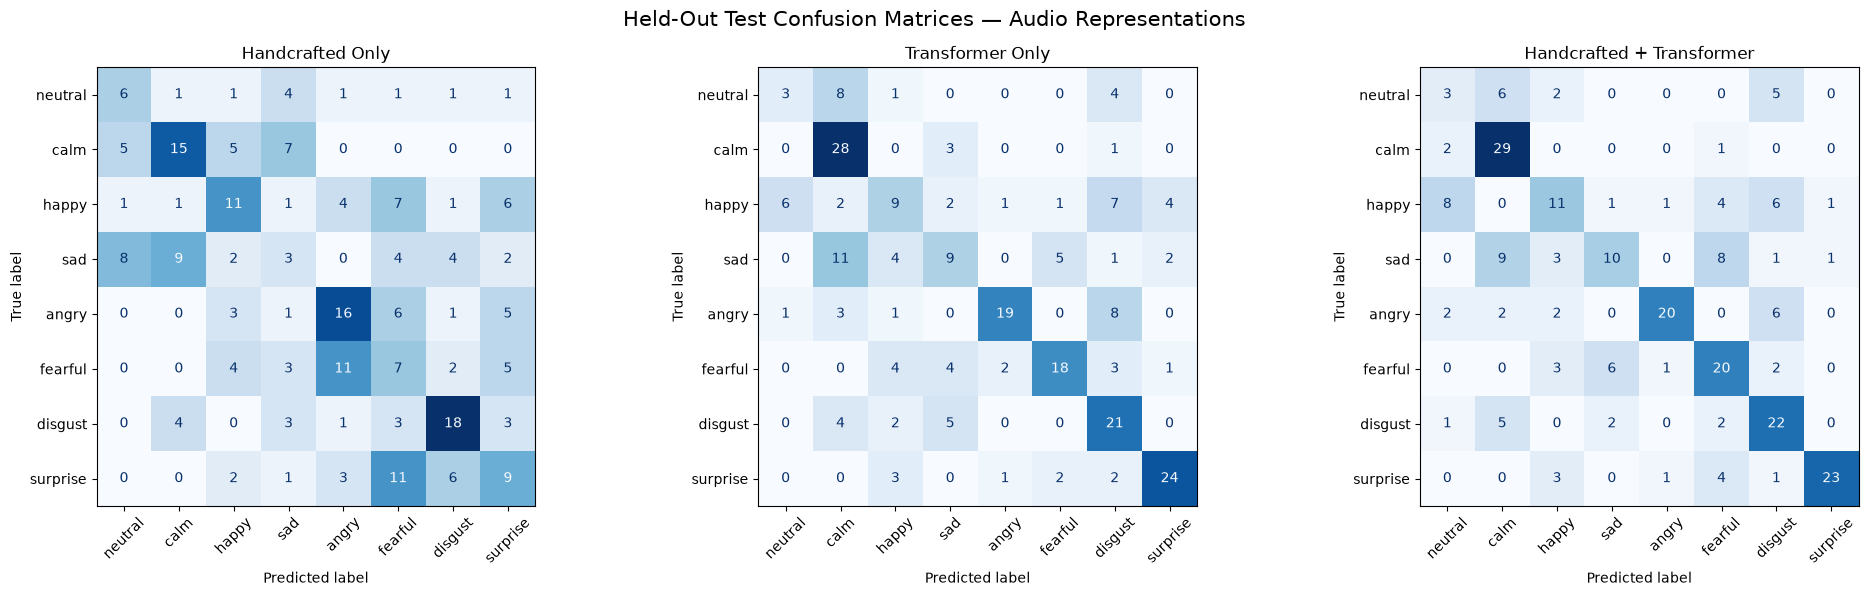

In [ ]:
# Compare the confusion matrices

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

titles = [
    "Handcrafted Only",
    "Transformer Only",
    "Handcrafted + Transformer",
]

for ax, model_name, title in zip(axes, models, titles):

    cm = pd.read_csv(
        METRICS_DIR / f"{model_name}_confusion_matrix.csv",
        index_col=0,
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm.to_numpy(),
        display_labels=class_names,
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        values_format="d",
    )

    ax.set_title(title)

plt.suptitle(
    "Held-Out Test Confusion Matrices — Audio Representations",
    fontsize=15,
)

plt.tight_layout()
plt.show()


In [ ]:
# Compare per-class F1 scores

per_class = []

for model_name in models:

    report = pd.read_csv(
        METRICS_DIR / f"{model_name}_classification_report.csv",
        index_col=0,
    )

    for emotion in class_names:
        per_class.append({
            "model": model_name,
            "emotion": emotion,
            "precision": report.loc[emotion, "precision"],
            "recall": report.loc[emotion, "recall"],
            "f1": report.loc[emotion, "f1-score"],
            "support": report.loc[emotion, "support"],
        })

per_class_df = pd.DataFrame(per_class)

f1_comparison = per_class_df.pivot(
    index="emotion",
    columns="model",
    values="f1",
)

display(f1_comparison.round(4))


model,handcrafted_only,handcrafted_transformer,transformer_only
emotion,,,
angry,0.4706,0.7273,0.6909
calm,0.4839,0.6988,0.6364
disgust,0.5538,0.5867,0.5316
fearful,0.1972,0.5634,0.6207
happy,0.3667,0.3929,0.3214
neutral,0.3333,0.1875,0.2308
sad,0.1091,0.3922,0.3273
surprise,0.2857,0.8070,0.7619


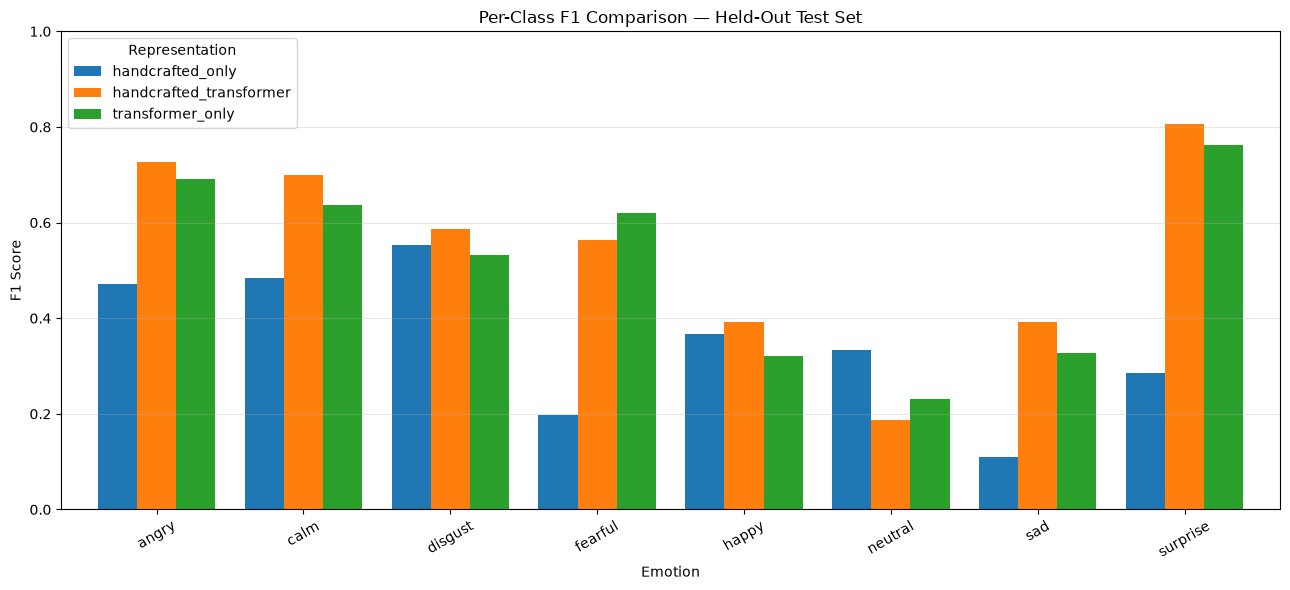

In [ ]:
# visualize the comparison:

ax = f1_comparison.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8,
)

ax.set_title("Per-Class F1 Comparison — Held-Out Test Set")
ax.set_ylabel("F1 Score")
ax.set_xlabel("Emotion")
ax.set_ylim(0, 1)
ax.legend(title="Representation")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [5]:
# Calculate improvement by emotion


f1_comparison["fusion_gain_over_transformer"] = (
    f1_comparison["handcrafted_transformer"]
    - f1_comparison["transformer_only"]
)

display(
    f1_comparison[
        [
            "transformer_only",
            "handcrafted_transformer",
            "fusion_gain_over_transformer",
        ]
    ].sort_values(
        "fusion_gain_over_transformer",
        ascending=False,
    ).round(4)
)


model,transformer_only,handcrafted_transformer,fusion_gain_over_transformer
emotion,,,
happy,0.3214,0.3929,0.0714
sad,0.3273,0.3922,0.0649
calm,0.6364,0.6988,0.0624
disgust,0.5316,0.5867,0.0550
surprise,0.7619,0.8070,0.0451
angry,0.6909,0.7273,0.0364
neutral,0.2308,0.1875,-0.0433
fearful,0.6207,0.5634,-0.0573


In [6]:
# Save the final analysis

output_path = METRICS_DIR / "per_class_f1_comparison.csv"

f1_comparison.to_csv(output_path)

print("Saved:", output_path)

Saved: d:\NUS AIS\Pattern Recognition Machine Learning System Project - 1\My Project Work\PRS Project\Member 1\M1_Audio_Handcrafted\outputs\metrics\per_class_f1_comparison.csv


In [7]:
from pathlib import Path
import pandas as pd

root = PROJECT_ROOT

features = pd.read_csv(
    root / "outputs/features/export/audio_fused_176d.csv"
)

probabilities = pd.concat(
    [
        pd.read_csv(
            root / f"outputs/probabilities/audio_probabilities_{split}.csv"
        )
        for split in ("train", "val", "test")
    ],
    ignore_index=True,
)

assert len(features) == len(probabilities) == 1440
assert features["trial_id"].is_unique
assert probabilities["trial_id"].is_unique

comparison = features[
    ["trial_id", "actor_id", "emotion_label", "split"]
].merge(
    probabilities[
        ["trial_id", "actor_id", "emotion_label", "split"]
    ],
    on="trial_id",
    how="outer",
    suffixes=("_features", "_probabilities"),
    indicator=True,
    validate="one_to_one",
)

assert (comparison["_merge"] == "both").all()

for col in ("actor_id", "emotion_label", "split"):
    assert (
        comparison[f"{col}_features"]
        == comparison[f"{col}_probabilities"]
    ).all()

print("All 1,440 feature and probability records match!")

All 1,440 feature and probability records match!
